# Pipeline Gardenia | Etapa 6: Data Mining (RFM e K-Means)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anlbp/Projeto-Gardenia-unifeob/blob/main/recursos/dados/notebook_dados_nao_filtrados/06_kmeans_rfm.ipynb)

**Lê:** `dw_gardenia_N.sqlite`, gerado pelo notebook 04 (por padrão em `{DRIVE_PASTA}/dw`).
**Gera:** `rfm_clientes_N.csv` (um cliente por linha, com o segmento) e `perfil_clusters_N.csv`, por padrão em `{DRIVE_PASTA}/ml`.

> Antes de rodar este notebook, rode o 03 e o 04.

## O que este notebook faz

Segmenta os clientes em grupos de comportamento parecido, em duas partes:

1. **RFM**: resume cada cliente em três números:
   - **R**ecência: há quantos dias foi a última compra (menor é melhor);
   - **F**requência: quantas compras fez;
   - **M**onetário: quanto gastou (valor líquido).
2. **K-Means**: algoritmo de agrupamento que junta clientes com R, F e M parecidos. Antes, as três medidas são padronizadas (mesma escala), senão o valor em reais dominaria o resultado.

## Decisões de modelagem

- **Compras canceladas ficam de fora** (`EXCLUIR_CANCELADAS = True`). Uma compra cancelada não é comportamento de compra de fato.
- **Clientes sem nenhuma compra não entram.** RFM só existe para quem comprou.
- **A recência é medida a partir do fim do período dos dados**, não de hoje. Assim o resultado não muda conforme o dia em que o notebook roda.
- **Frequência e valor passam por `log1p` antes de padronizar** (`USAR_LOG = True`), porque são muito assimétricos: poucos clientes gastam muito mais que os outros, e isso distorceria os grupos.

## 1. Configuração e carga

In [1]:
# ============================ CONFIGURAÇÃO ============================
FONTE_DW = "drive"          # "drive" | "github" | "upload" | "local"
LOTE = "1"                  # mesmo lote usado nos notebooks 03, 04 e 05

DRIVE_PASTA = "/content/drive/MyDrive/gardenia"   # o 04 grava em {DRIVE_PASTA}/dw

# --- usado quando FONTE_DW == "github" (o .sqlite versionado no repositório) ---
GITHUB_USUARIO = "Anlbp"
GITHUB_REPO    = "Projeto-Gardenia-unifeob"
GITHUB_BRANCH  = "main"
PASTA_GITHUB   = "recursos/dados/dw"

# --- usado quando FONTE_DW == "local" ---
PASTA_LOCAL = "dw"

# --- modelo ---
EXCLUIR_CANCELADAS = True   # True: compras canceladas não contam no RFM
USAR_LOG = True             # True: aplica log1p em frequência e valor antes de padronizar
K_FINAL = 3                 # número de segmentos. None = usa o K de maior silhouette (entre 2 e 7)
SEMENTE = 42                # fixa o sorteio inicial do K-Means, para o resultado se repetir

# --- saída ---
SALVAR_NO_DRIVE = True      # True: grava em {DRIVE_PASTA}/ml
SAIDA = "ml"                # pasta usada quando SALVAR_NO_DRIVE = False
# =======================================================================

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
import shutil
import sqlite3
import urllib.error
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.options.display.float_format = "{:,.2f}".format

nome_db = f"dw_gardenia_{LOTE}.sqlite"
LOCAL_DB = "dw_trabalho.sqlite"   # cópia local: abrir o SQLite direto no Drive é lento

try:
    if FONTE_DW == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        shutil.copy(f"{DRIVE_PASTA}/dw/{nome_db}", LOCAL_DB)

    elif FONTE_DW == "github":
        branch = GITHUB_BRANCH.removeprefix("tree/")
        url = f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{GITHUB_REPO}/{branch}/{PASTA_GITHUB}/{nome_db}"
        print("baixando", url)
        urllib.request.urlretrieve(url, LOCAL_DB)

    elif FONTE_DW == "upload":
        from google.colab import files
        print(f"Selecione o arquivo {nome_db} gerado pelo notebook 04")
        files.upload()
        shutil.copy(nome_db, LOCAL_DB)

    elif FONTE_DW == "local":
        shutil.copy(f"{PASTA_LOCAL}/{nome_db}", LOCAL_DB)

    else:
        raise ValueError('FONTE_DW deve ser "drive", "github", "upload" ou "local".')

except (FileNotFoundError, urllib.error.HTTPError):
    raise FileNotFoundError(
        f"Não encontrei o DW ({nome_db}).\n"
        "Rode antes os notebooks 03 e 04 com o mesmo LOTE. "
        "Se o arquivo está em outro lugar, ajuste FONTE_DW e as pastas na configuração."
    ) from None

consulta = '''
SELECT f.id_compra, f.id_cliente, f.status, f.valor_liquido,
       d.data, p.categoria, c.faixa_etaria
FROM fato_vendas f
JOIN dim_data    d ON d.id_data    = f.id_data
JOIN dim_produto p ON p.id_produto = f.id_produto
JOIN dim_cliente c ON c.id_cliente = f.id_cliente
'''
con = sqlite3.connect(LOCAL_DB)
vendas = pd.read_sql(consulta, con, parse_dates=["data"])
n_clientes_dw = con.execute("SELECT COUNT(*) FROM dim_cliente").fetchone()[0]
con.close()

print(f"{len(vendas)} compras no DW, de {vendas['id_cliente'].nunique()} clientes (de {n_clientes_dw} cadastrados)")
vendas.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1184 compras no DW, de 1063 clientes (de 5000 cadastrados)


,id_compra,id_cliente,status,valor_liquido,data,categoria,faixa_etaria
0,1_15,1_4487,entregue,"3,027.04",2026-09-09,Roupas,45-54
1,1_16,1_3240,cancelado,440.95,2026-05-23,Livros,25-34
2,1_21,1_2478,enviado,"2,725.46",2026-05-29,Eletrônicos,45-54
3,1_26,1_3167,pendente,"1,894.27",2026-08-06,Esportes,45-54
4,1_28,1_2381,enviado,"3,729.57",2026-02-13,Casa,35-44


## 2. RFM por cliente

Uma linha por cliente, com recência, frequência e valor. A **data de referência** é o dia seguinte à última compra dos dados.

In [5]:
base = vendas[vendas["status"] != "cancelado"] if EXCLUIR_CANCELADAS else vendas
n_canceladas = len(vendas) - len(base)

data_ref = base["data"].max().normalize() + pd.Timedelta(days=1)

rfm = base.groupby("id_cliente").agg(
    recencia=("data", lambda x: (data_ref - x.max()).days),
    frequencia=("id_compra", "count"),
    monetario=("valor_liquido", "sum"),
).reset_index()

assert len(rfm) >= 10, "poucos clientes com compra para segmentar"
print(f"Data de referência: {data_ref.date()}")
if EXCLUIR_CANCELADAS:
    print(f"Compras canceladas descartadas: {n_canceladas}")
print(f"Clientes com compra: {len(rfm)} de {n_clientes_dw} ({100 * len(rfm) / n_clientes_dw:.1f}%)")
print(f"Clientes sem compra (fora da segmentação): {n_clientes_dw - len(rfm)}\n")
display(rfm[["recencia", "frequencia", "monetario"]].describe().T)

dist_freq = rfm["frequencia"].value_counts().sort_index()
print("Clientes por número de compras:", dist_freq.to_dict())
unica = 100 * (rfm["frequencia"] == 1).mean()
if unica > 80:
    print(f"\nAtenção: {unica:.0f}% dos clientes compraram só uma vez. A frequência quase não varia, "
          "então os segmentos serão definidos sobretudo por recência e valor. "
          "Isso é esperado depois da limpeza (poucas compras sobram por cliente) e melhora com um lote maior.")

Data de referência: 2026-10-10
Compras canceladas descartadas: 246
Clientes com compra: 868 de 5000 (17.4%)
Clientes sem compra (fora da segmentação): 4132



,count,mean,std,min,25%,50%,75%,max
recencia,868.00,177.79,106.01,1.00,87.00,175.00,268.25,366.00
frequencia,868.00,1.08,0.28,1.00,1.00,1.00,1.00,3.00
monetario,868.00,"2,244.31","1,472.95",8.31,"1,074.00","2,086.31","3,214.17","11,414.25"


Clientes por número de compras: {1: 800, 2: 66, 3: 2}

Atenção: 92% dos clientes compraram só uma vez. A frequência quase não varia, então os segmentos serão definidos sobretudo por recência e valor. Isso é esperado depois da limpeza (poucas compras sobram por cliente) e melhora com um lote maior.


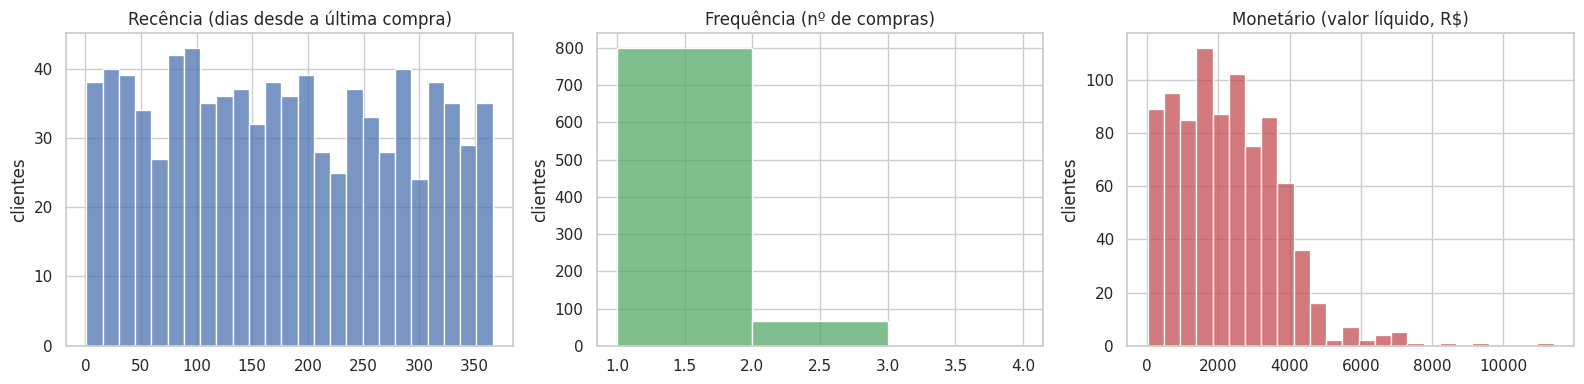

Recência mediana: 175 dias. Valor mediano por cliente: R$ 2,086.31, máximo R$ 11,414.25 (assimetria: média R$ 2,244.31).


In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, cor, tit in [(eixos[0], "recencia", "#4C72B0", "Recência (dias desde a última compra)"),
                          (eixos[1], "frequencia", "#55A868", "Frequência (nº de compras)"),
                          (eixos[2], "monetario", "#C44E52", "Monetário (valor líquido, R$)")]:
    sns.histplot(rfm[col], bins=25 if col != "frequencia" else range(1, int(rfm[col].max()) + 2), color=cor, ax=ax)
    ax.set(title=tit, xlabel="", ylabel="clientes")
plt.tight_layout()
plt.show()

print(f"Recência mediana: {rfm['recencia'].median():.0f} dias. Valor mediano por cliente: R$ {rfm['monetario'].median():,.2f}, "
      f"máximo R$ {rfm['monetario'].max():,.2f} (assimetria: média R$ {rfm['monetario'].mean():,.2f}).")

## 3. Preparar os dados e escolher o K

O K-Means precisa que se diga **quantos grupos (K)** formar. Dois critérios ajudam:

- **Cotovelo (inércia):** quanto mais grupos, menor a distância dentro de cada grupo. O ponto onde a queda "dobra" sugere um K razoável.
- **Silhouette:** de -1 a 1, mede se cada cliente está mais perto do próprio grupo do que dos outros. Quanto mais alto, melhor separados os grupos.

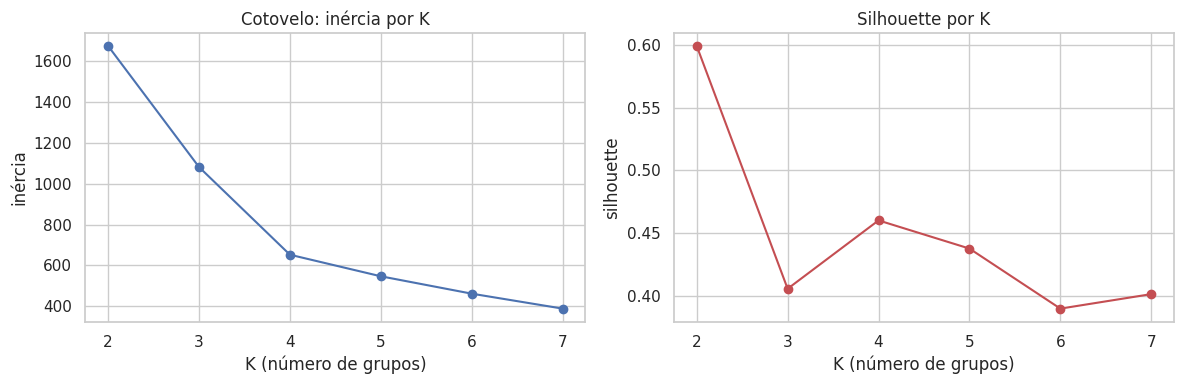

 K  inercia  silhouette
 2 1,674.86        0.60
 3 1,081.65        0.41
 4   652.10        0.46
 5   546.38        0.44
 6   461.23        0.39
 7   388.01        0.40

Maior silhouette em K = 2 (0.599).
K usado no modelo final: 3 (definido em K_FINAL)


In [7]:
X_bruto = rfm[["recencia", "frequencia", "monetario"]].astype(float).copy()
if USAR_LOG:
    X_bruto["frequencia"] = np.log1p(X_bruto["frequencia"])
    X_bruto["monetario"] = np.log1p(X_bruto["monetario"])

X = StandardScaler().fit_transform(X_bruto)

ks = list(range(2, 8))
inercia, silhueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10).fit(X)
    inercia.append(km.inertia_)
    silhueta.append(silhouette_score(X, km.labels_))

k_sugerido = ks[int(np.argmax(silhueta))]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(ks, inercia, marker="o", color="#4C72B0")
eixos[0].set(title="Cotovelo: inércia por K", xlabel="K (número de grupos)", ylabel="inércia")
eixos[1].plot(ks, silhueta, marker="o", color="#C44E52")
eixos[1].set(title="Silhouette por K", xlabel="K (número de grupos)", ylabel="silhouette")
for ax in eixos:
    ax.set_xticks(ks)
plt.tight_layout()
plt.show()

K = k_sugerido if K_FINAL is None else K_FINAL
print(pd.DataFrame({"K": ks, "inercia": inercia, "silhouette": silhueta}).to_string(index=False))
print(f"\nMaior silhouette em K = {k_sugerido} ({max(silhueta):.3f}).")
print(f"K usado no modelo final: {K}" + (" (definido em K_FINAL)" if K_FINAL is not None else " (escolhido pelo silhouette)"))

## 4. Modelo final e nomes dos segmentos

O K-Means numera os grupos de forma arbitrária (0, 1, 2). Para dar nomes, cada grupo recebe uma **nota**: recência baixa, frequência alta e valor alto somam pontos. O grupo de maior nota vira **VIP**, o de menor vira **Baixo engajamento**, e os do meio viram **Regular**.

In [8]:
km = KMeans(n_clusters=K, random_state=SEMENTE, n_init=10).fit(X)
rfm["cluster"] = km.labels_
sil_final = silhouette_score(X, km.labels_)

# nota de cada grupo: média das medidas padronizadas (recência pesa ao contrário)
z = pd.DataFrame(X, columns=["r", "f", "m"]).assign(cluster=km.labels_).groupby("cluster").mean()
nota = (-z["r"] + z["f"] + z["m"]).sort_values()          # do pior para o melhor
if K == 2:
    nomes = ["Baixo engajamento", "VIP"]
elif K == 3:
    nomes = ["Baixo engajamento", "Regular", "VIP"]
else:
    nomes = ["Baixo engajamento"] + [f"Regular {i}" for i in range(1, K - 1)] + ["VIP"]
mapa_nome = dict(zip(nota.index, nomes))
rfm["segmento"] = rfm["cluster"].map(mapa_nome)

if sil_final >= 0.5:
    leitura = "grupos bem separados"
elif sil_final >= 0.25:
    leitura = "separação razoável: os grupos existem, mas se tocam nas bordas"
else:
    leitura = "separação fraca: os grupos se sobrepõem bastante e devem ser lidos como tendências, não como categorias nítidas"
print(f"Silhouette do modelo final: {sil_final:.3f} ({leitura}).")
print("\nClientes por segmento:")
print(rfm["segmento"].value_counts()[nomes[::-1]].to_string())

Silhouette do modelo final: 0.406 (separação razoável: os grupos existem, mas se tocam nas bordas).

Clientes por segmento:
segmento
VIP          68
Regular     422
Baixo engajamento    378


## 5. Perfil dos segmentos

Médias de R, F e M por segmento, o peso de cada um no valor total e quem são os clientes (faixa etária e categoria mais compradas).

In [9]:
ordem_seg = nomes[::-1]   # VIP primeiro

perfil = rfm.groupby("segmento").agg(
    clientes=("id_cliente", "count"),
    recencia_media=("recencia", "mean"),
    frequencia_media=("frequencia", "mean"),
    valor_medio=("monetario", "mean"),
    valor_total=("monetario", "sum"),
).reindex(ordem_seg)
perfil["% clientes"] = 100 * perfil["clientes"] / perfil["clientes"].sum()
perfil["% do valor"] = 100 * perfil["valor_total"] / perfil["valor_total"].sum()

# quem são: faixa etária mais comum (entre os clientes do segmento) e categoria de maior valor
base_seg = base.merge(rfm[["id_cliente", "segmento"]], on="id_cliente")
faixa = (base_seg.drop_duplicates("id_cliente").groupby("segmento")["faixa_etaria"]
         .agg(lambda s: s.value_counts().idxmax()))
categoria = base_seg.groupby(["segmento", "categoria"])["valor_liquido"].sum().reset_index()
categoria = categoria.loc[categoria.groupby("segmento")["valor_liquido"].idxmax()].set_index("segmento")["categoria"]
perfil["faixa_etaria_comum"] = faixa
perfil["categoria_top"] = categoria

display(perfil)

top = perfil.iloc[0]
print(f"VIP: {top['% clientes']:.1f}% dos clientes geram {top['% do valor']:.1f}% do valor.")

,clientes,recencia_media,frequencia_media,valor_medio,valor_total,% clientes,% do valor,faixa_etaria_comum,categoria_top
segmento,,,,,,,,,
VIP,68,125.82,2.03,"4,444.50","302,226.04",7.83,15.51,65+,Casa
Regular,422,96.33,1.00,"1,957.49","826,062.14",48.62,42.40,65+,Esportes
Baixo engajamento,378,278.07,1.00,"2,168.70","819,770.12",43.55,42.08,65+,Livros


VIP: 7.8% dos clientes geram 15.5% do valor.


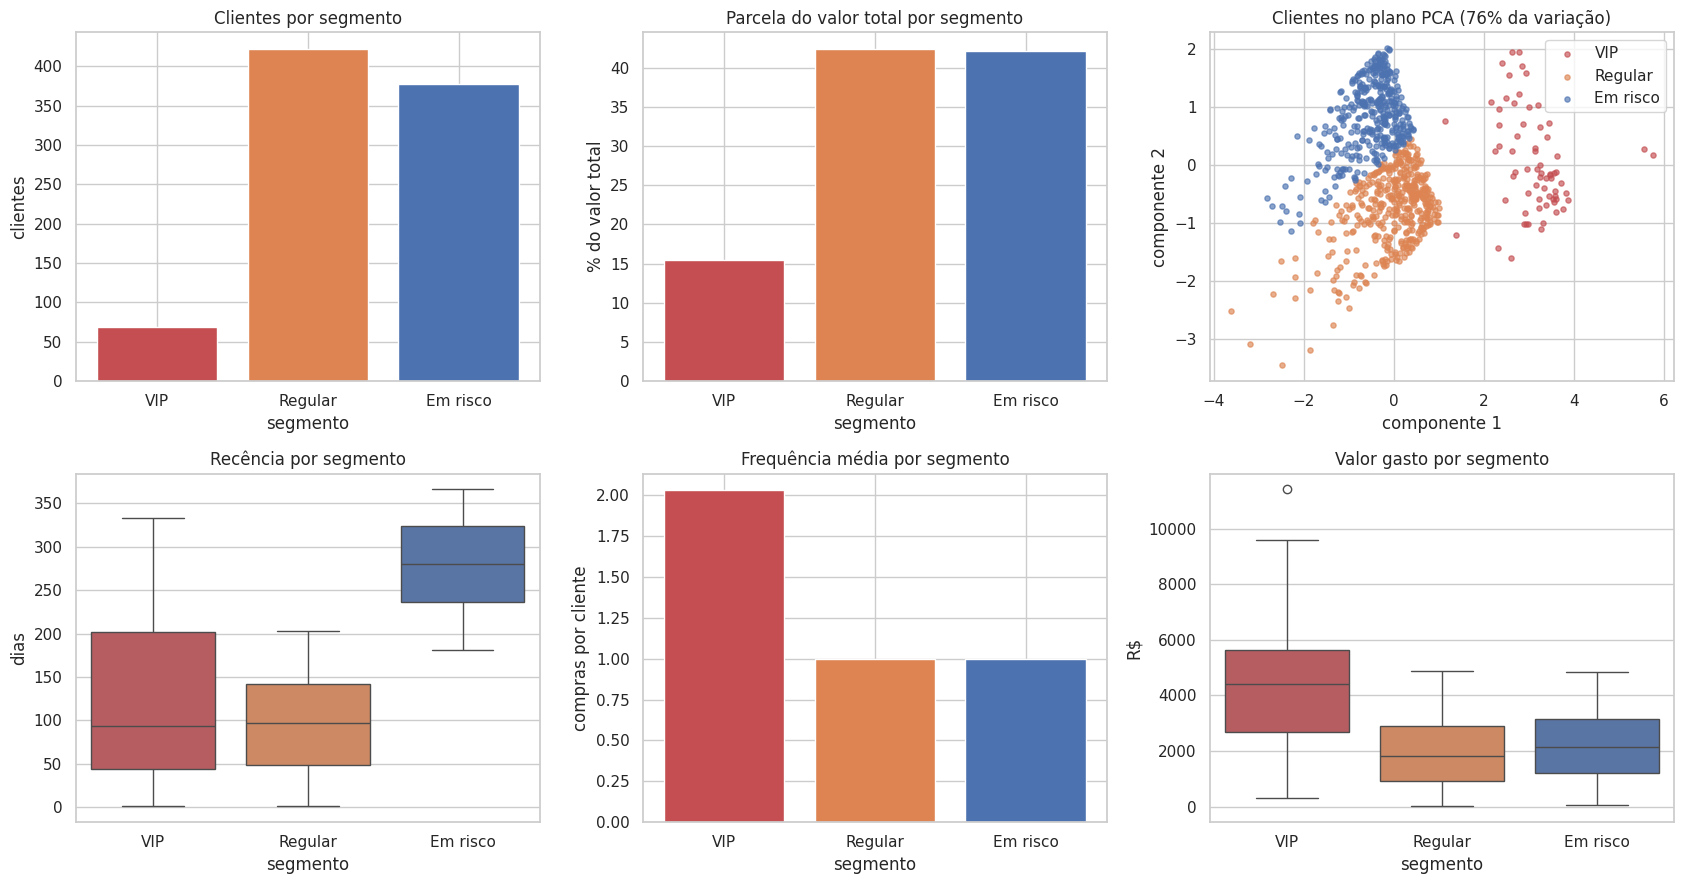

VIP: 68 clientes, última compra há 126 dias em média, 2.03 compra(s) e R$ 4,444.50 por cliente.
Regular: 422 clientes, última compra há 96 dias em média, 1.00 compra(s) e R$ 1,957.49 por cliente.
Baixo engajamento: 378 clientes, última compra há 278 dias em média, 1.00 compra(s) e R$ 2,168.70 por cliente.


In [10]:
cores = {"VIP": "#C44E52", "Regular": "#DD8452", "Baixo engajamento": "#4C72B0"}
for i in range(1, K - 1):
    cores[f"Regular {i}"] = ["#DD8452", "#55A868", "#8172B3", "#937860"][(i - 1) % 4]
paleta = {s: cores.get(s, "#888888") for s in ordem_seg}

fig, eixos = plt.subplots(2, 3, figsize=(17, 9))

# tamanho e peso no valor
eixos[0, 0].bar(perfil.index, perfil["clientes"], color=[paleta[s] for s in perfil.index])
eixos[0, 0].set(title="Clientes por segmento", xlabel="segmento", ylabel="clientes")
eixos[0, 1].bar(perfil.index, perfil["% do valor"], color=[paleta[s] for s in perfil.index])
eixos[0, 1].set(title="Parcela do valor total por segmento", xlabel="segmento", ylabel="% do valor total")

# PCA: os 3 eixos (R, F, M) resumidos em 2 para poder desenhar
pca = PCA(n_components=2, random_state=SEMENTE)
pontos = pca.fit_transform(X)
for seg in ordem_seg:
    m = (rfm["segmento"] == seg).values
    eixos[0, 2].scatter(pontos[m, 0], pontos[m, 1], s=14, alpha=0.65, color=paleta[seg], label=seg)
eixos[0, 2].set(title=f"Clientes no plano PCA ({100 * pca.explained_variance_ratio_.sum():.0f}% da variação)",
                xlabel="componente 1", ylabel="componente 2")
eixos[0, 2].legend()

# distribuição de cada medida por segmento
sns.boxplot(data=rfm, x="segmento", y="recencia", order=ordem_seg, palette=paleta, hue="segmento", legend=False, ax=eixos[1, 0])
eixos[1, 0].set(title="Recência por segmento", xlabel="segmento", ylabel="dias")
eixos[1, 1].bar(perfil.index, perfil["frequencia_media"], color=[paleta[s] for s in perfil.index])
eixos[1, 1].set(title="Frequência média por segmento", xlabel="segmento", ylabel="compras por cliente")
sns.boxplot(data=rfm, x="segmento", y="monetario", order=ordem_seg, palette=paleta, hue="segmento", legend=False, ax=eixos[1, 2])
eixos[1, 2].set(title="Valor gasto por segmento", xlabel="segmento", ylabel="R$")

plt.tight_layout()
plt.show()

for seg in ordem_seg:
    p = perfil.loc[seg]
    print(f"{seg}: {int(p['clientes'])} clientes, última compra há {p['recencia_media']:.0f} dias em média, "
          f"{p['frequencia_media']:.2f} compra(s) e R$ {p['valor_medio']:,.2f} por cliente.")

## 6. Leitura dos segmentos e ações sugeridas

| Segmento | Quem é | Ação sugerida |
|---|---|---|
| **VIP** | compram mais vezes e gastam mais (neste lote, a recência não é a melhor) | benefícios exclusivos, acesso antecipado a lançamentos, programa de fidelidade |
| **Regular** | meio-termo em recência e valor | incentivar a segunda compra: cupom no prazo certo, recomendação de produtos da mesma categoria |
| **Baixo engajamento** | última compra antiga (o valor pode ser alto, como neste lote) | campanha de reativação com desconto limitado; priorizar pelo valor já gasto, não só pela recência |

As tabelas e gráficos acima mostram qual grupo recebeu cada nome neste lote. Confira o perfil antes de usar o rótulo: o nome vem de uma nota calculada, não de uma análise humana.

> **Limite do modelo.** O silhouette da seção 4 diz o quanto os grupos são distintos. Se ficou abaixo de 0,25, trate os segmentos como uma forma de organizar os clientes, não como categorias que a loja deva tomar como verdade.

## 7. Salvar os resultados

`rfm_clientes_N.csv` serve de entrada para a Etapa 8 (insights) e para qualquer análise posterior por cliente.

In [11]:
if SALVAR_NO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        SAIDA = f"{DRIVE_PASTA}/ml"
    except ImportError:
        print("Fora do Colab: salvando na pasta local", SAIDA)
os.makedirs(SAIDA, exist_ok=True)

assert rfm["segmento"].notna().all() and len(rfm) == rfm["id_cliente"].nunique()

saidas = {
    f"rfm_clientes_{LOTE}.csv": rfm[["id_cliente", "recencia", "frequencia", "monetario", "cluster", "segmento"]],
    f"perfil_clusters_{LOTE}.csv": perfil.reset_index(),
    f"avaliacao_k_{LOTE}.csv": pd.DataFrame({"K": ks, "inercia": inercia, "silhouette": silhueta}),
}
for nome, df in saidas.items():
    df.to_csv(f"{SAIDA}/{nome}", index=False)
    print(f"{SAIDA}/{nome:28s} {len(df):>5} linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/gardenia/ml/rfm_clientes_1.csv             868 linhas
/content/drive/MyDrive/gardenia/ml/perfil_clusters_1.csv            3 linhas
/content/drive/MyDrive/gardenia/ml/avaliacao_k_1.csv                6 linhas


## Próximos passos

**Etapa 7: Spark.** Repetir uma agregação (por exemplo, valor por categoria) com processamento distribuído sobre os arquivos acumulados dos ciclos.

Checklist antes do commit:

- [ ] os notebooks 03 e 04 foram rodados antes, com o mesmo `LOTE`;
- [ ] a coluna `inconsistente` não aparece em nenhuma etapa do RFM;
- [ ] o K foi justificado com cotovelo e silhouette, e o silhouette final foi comentado;
- [ ] os gráficos têm título, eixos rotulados e uma frase de interpretação;
- [ ] o limite da frequência (muitos clientes com uma única compra) está registrado no relatório.